BURGERS MIXED-K PAD17 | SCALING + CONTEXT INTERVENTION
Device     : cpu
Dataset    : /kaggle/input/notebooks/xinyuanli913/dataset-box-ood/all8families_box_linear_id_ampood_recorded.mat
Checkpoint : /kaggle/input/notebooks/xinyuanli913/burgers-training-padding/burgers_box_linear_mixedK_pad17/burgers_box_linear_mixedK_pad17_train1to5_testfixed5_final_epoch300.pt
Output dir : /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only

[checkpoint audit]
  seed             : 42
  D_MODEL          : 96
  heads            : 4
  layers           : 3
  D_FF             : 192
  dropout          : 0.1
  row width        : 100
  row types        : 5
  max ctx rows     : 17
  train operators  : 560
  held-out operators: 240

[dataset audit]
  uc : (800, 100, 100)
  uf : (800, 100, 100)
  x  : (100,)
  uc preprocessing: NONE

[model loaded]
  parameters: 255,364

Fixed 1024-case family counts: [111, 120, 132, 114, 139, 134, 139, 135]
Family-count audit: PASS

SCALING K=1,...,5


/tmp/ipykernel_17/922596246.py:575: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


K=1:   0%|          | 0/4 [00:00<?, ?it/s]

K=2:   0%|          | 0/4 [00:00<?, ?it/s]

K=3:   0%|          | 0/4 [00:00<?, ?it/s]

K=4:   0%|          | 0/4 [00:00<?, ?it/s]

... (2 outputs left out)

correct:   0%|          | 0/4 [00:00<?, ?it/s]

wrong_operator_full:   0%|          | 0/4 [00:00<?, ?it/s]

wrong_uf_only:   0%|          | 0/4 [00:00<?, ?it/s]


Context intervention results:
            Context  K  Pred RelL2 mean (%)  Pred RelL2 median (%)  Pred RelL2 std (%)  Mean increase vs correct (pp)  Mean ratio vs correct  Worse cases (%)
            correct  5               3.6559                 3.3652              2.1458                            NaN                 1.0000              NaN
wrong_operator_full  5              11.5221                 7.1704             10.2691                         7.8662                 3.1516          86.0352
      wrong_uf_only  5              11.2752                 7.5466              9.3385                         7.6193                 3.0841          89.9414

Correct-context vs K=5 consistency: PASS


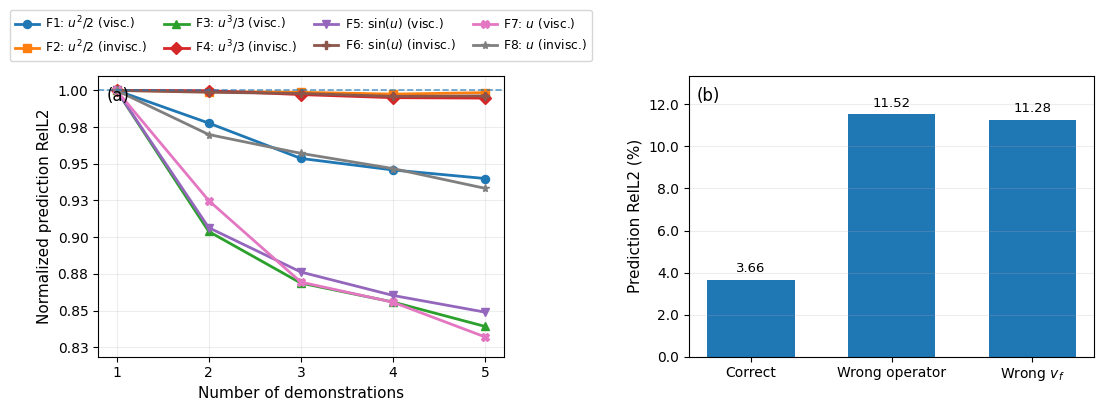


Saved:
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_scaling_all_cases.csv
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_scaling_summary.csv
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_scaling_normalized_by_family.csv
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_context_all_cases.csv
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_context_summary.csv
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_mixedK_pad17_normalized_scaling_context_sidebyside.pdf
  /kaggle/working/burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only/burgers_mixedK_pad17_normalized_scaling_context_sidebyside.png

DONE.


In [1]:
# ============================================================
# KAGGLE ONE-CELL
# BURGERS MIXED-K PAD17:
#   1) FAMILY-WISE SCALING K=1,...,5
#   2) CONTEXT INTERVENTION
#   3) PAPER FIGURE (same style/protocol as previous Burgers code)
#
# ONLY REQUIRED INPUTS:
#   - checkpoint folder
#   - dataset folder
#
# NO RETRAINING
# NO PRECOMPUTED CSV
# NO ASSUMPTION THAT ROW-TYPE CONSTANTS ARE SAVED IN cfg
#
# IMPORTANT:
# This preserves the context protocol from the user's previous
# scaling/context code:
#   wrong_operator_full:
#       another held-out operator in the SAME PDE family,
#       same demo IC indices, replace both Uc and Uf
#   wrong_uf_only:
#       keep correct Uc, replace only Uf using the same paired
#       wrong operator and same demo IC indices
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import scipy.io as sio

import torch
import torch.nn as nn

import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

from tqdm.auto import tqdm


# ============================================================
# 0. USER PATHS -- ONLY THINGS YOU NEED TO EDIT
# ============================================================

DATASET_DIR = Path(
    "/kaggle/input/notebooks/xinyuanli913/dataset-box-ood"
)

CKPT_DIR = Path(
    "/kaggle/input/notebooks/xinyuanli913/burgers-training-padding"
)

DATASET_FILENAME = (
    "all8families_box_linear_id_ampood_recorded.mat"
)

OUT_DIR = Path(
    "/kaggle/working/"
    "burgers_mixedK_pad17_scaling_context_from_ckpt_dataset_only"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PDF_PATH = (
    OUT_DIR
    / "burgers_mixedK_pad17_normalized_scaling_context_sidebyside.pdf"
)

PNG_PATH = (
    OUT_DIR
    / "burgers_mixedK_pad17_normalized_scaling_context_sidebyside.png"
)


# ============================================================
# 1. FIXED FORMAL EVALUATION SETTINGS
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

N_TEST_CASES = 1024
K_MAX = 5
EVAL_BATCH_SIZE = 256
EPS = 1e-8

N_FAM = 8
N_VAR = 100
N_IC = 100

# These are the canonical row-type IDs used by the Burgers model.
# They do NOT need to exist in checkpoint cfg.
TYPE_X_DEMO = 0
TYPE_UC_DEMO = 1
TYPE_UF_DEMO = 2
TYPE_X_QUERY = 3
TYPE_UC_QUERY = 4

EXPECTED_FAMILY_COUNTS = [
    111,
    120,
    132,
    114,
    139,
    134,
    139,
    135,
]


# ============================================================
# 2. FIND DATASET
# ============================================================

dataset_candidates = list(
    DATASET_DIR.rglob(
        DATASET_FILENAME
    )
)

if len(dataset_candidates) != 1:

    print("\nDataset candidates:")

    for p in DATASET_DIR.rglob("*.mat"):
        print(" ", p)

    raise RuntimeError(
        f"Expected exactly one {DATASET_FILENAME}, "
        f"found {len(dataset_candidates)}."
    )

MAT_PATH = dataset_candidates[0]


# ============================================================
# 3. FIND NEW MIXED-K PAD17 FINAL CHECKPOINT
# ============================================================

all_ckpts = sorted(
    CKPT_DIR.rglob("*.pt")
)

preferred = [
    p
    for p in all_ckpts
    if (
        "mixedK_pad17" in p.name
        and "final_epoch300" in p.name
    )
]

if len(preferred) != 1:

    preferred = [
        p
        for p in all_ckpts
        if (
            "mixedK_pad17" in str(p)
            and "final" in p.name.lower()
        )
    ]

if len(preferred) != 1:

    print("\nCheckpoint candidates:")

    for p in all_ckpts:
        print(" ", p)

    raise RuntimeError(
        "Could not uniquely identify the final mixed-K pad17 checkpoint."
    )

CKPT_PATH = preferred[0]


print("=" * 108)
print(
    "BURGERS MIXED-K PAD17 | SCALING + CONTEXT INTERVENTION"
)
print("=" * 108)
print("Device     :", DEVICE)
print("Dataset    :", MAT_PATH)
print("Checkpoint :", CKPT_PATH)
print("Output dir :", OUT_DIR)
print("=" * 108)


# ============================================================
# 4. LOAD CHECKPOINT
# ============================================================

try:

    ckpt = torch.load(
        CKPT_PATH,
        map_location="cpu",
        weights_only=False,
    )

except TypeError:

    ckpt = torch.load(
        CKPT_PATH,
        map_location="cpu",
    )


state = ckpt.get(
    "model",
    ckpt.get(
        "model_state_dict",
        None,
    ),
)

if state is None:
    raise KeyError(
        "Checkpoint contains neither 'model' nor 'model_state_dict'."
    )

cfg = ckpt.get(
    "config",
    {},
)

norm = ckpt.get(
    "norm",
    None,
)

if norm is None:
    raise KeyError(
        "Checkpoint does not contain normalization dictionary 'norm'."
    )


# ============================================================
# 5. RECOVER EVERYTHING POSSIBLE FROM CHECKPOINT ITSELF
# ============================================================

# Training seed
TRAIN_SEED = int(
    cfg.get(
        "SEED",
        42,
    )
)

# Architecture inferred directly from state dict
NX = int(
    state[
        "row_in.weight"
    ].shape[1]
)

D_MODEL = int(
    state[
        "row_in.weight"
    ].shape[0]
)

N_ROW_TYPES = int(
    state[
        "row_type_emb.weight"
    ].shape[0]
)

MAX_CTX_ROWS = int(
    state[
        "pos_emb.weight"
    ].shape[0]
)

D_FF = int(
    state[
        "encoder.layers.0.linear1.weight"
    ].shape[0]
)

layer_ids = sorted(
    {
        int(k.split(".")[2])
        for k in state
        if k.startswith(
            "encoder.layers."
        )
    }
)

N_LAYERS = len(
    layer_ids
)

# Number of heads cannot be recovered from parameter shapes.
# Use checkpoint config if present; canonical model uses 4.
N_HEAD = int(
    cfg.get(
        "N_HEAD",
        4,
    )
)

DROPOUT = float(
    cfg.get(
        "DROPOUT",
        0.10,
    )
)

if NX != 100:
    raise RuntimeError(
        f"Expected NX=100, got {NX}."
    )

if N_ROW_TYPES != 5:
    raise RuntimeError(
        f"Expected 5 row types, got {N_ROW_TYPES}."
    )

if MAX_CTX_ROWS < 17:
    raise RuntimeError(
        f"Expected max context length >=17, got {MAX_CTX_ROWS}."
    )


# ------------------------------------------------------------
# Operator split
# ------------------------------------------------------------

if (
    "train_ops" not in cfg
    or "test_ops" not in cfg
):
    raise KeyError(
        "Checkpoint config does not contain train_ops/test_ops. "
        "These are required to reproduce the exact formal held-out split."
    )

train_ops = np.asarray(
    cfg["train_ops"],
    dtype=np.int64,
)

test_ops = np.asarray(
    cfg["test_ops"],
    dtype=np.int64,
)

all_ics = np.asarray(
    cfg.get(
        "all_ics",
        np.arange(
            N_IC,
            dtype=np.int64,
        ),
    ),
    dtype=np.int64,
)

assert len(train_ops) == 560
assert len(test_ops) == 240
assert len(all_ics) == 100


# ------------------------------------------------------------
# Normalization
# ------------------------------------------------------------

x_mean = float(
    norm["x_mean"]
)

x_std = float(
    norm["x_std"]
)

uc_mean = float(
    norm["uc_mean"]
)

uc_std = float(
    norm["uc_std"]
)

uf_mean = float(
    norm["uf_mean"]
)

uf_std = float(
    norm["uf_std"]
)


print("\n[checkpoint audit]")
print("  seed             :", TRAIN_SEED)
print("  D_MODEL          :", D_MODEL)
print("  heads            :", N_HEAD)
print("  layers           :", N_LAYERS)
print("  D_FF             :", D_FF)
print("  dropout          :", DROPOUT)
print("  row width        :", NX)
print("  row types        :", N_ROW_TYPES)
print("  max ctx rows     :", MAX_CTX_ROWS)
print("  train operators  :", len(train_ops))
print("  held-out operators:", len(test_ops))


# ============================================================
# 6. LOAD DIRECT-LINEAR DATASET
# ============================================================

mat = sio.loadmat(
    MAT_PATH
)

for key in [
    "x",
    "uc_id",
    "uf_id",
]:

    if key not in mat:

        raise KeyError(
            f"Missing dataset key: {key}"
        )


x_grid = np.asarray(
    mat["x"],
    dtype=np.float32,
).squeeze()

uc_raw = np.asarray(
    mat["uc_id"],
    dtype=np.float32,
)

uf_raw = np.asarray(
    mat["uf_id"],
    dtype=np.float32,
)


assert uc_raw.shape == (
    8,
    100,
    100,
    100,
)

assert uf_raw.shape == (
    8,
    100,
    100,
    100,
)

assert x_grid.shape == (
    100,
)


# uc_id is ALREADY the direct-linear 50 -> 100 representation.
# DO NOT interpolate/deblock again.

uc = uc_raw.reshape(
    N_FAM * N_VAR,
    N_IC,
    NX,
)

uf = uf_raw.reshape(
    N_FAM * N_VAR,
    N_IC,
    NX,
)


x_n = (
    (x_grid - x_mean)
    / x_std
).astype(
    np.float32
)

uc_n = (
    (uc - uc_mean)
    / uc_std
).astype(
    np.float32
)

uf_n = (
    (uf - uf_mean)
    / uf_std
).astype(
    np.float32
)


print("\n[dataset audit]")
print("  uc :", uc.shape)
print("  uf :", uf.shape)
print("  x  :", x_grid.shape)
print("  uc preprocessing: NONE")


# ============================================================
# 7. MODEL
#
# Evaluation uses the learned parameterization with exact sequence
# length for each K. Padding was a TRAINING batching device only.
# ============================================================

class RowSequenceWholeBlockShiftTransformer(
    nn.Module
):

    def __init__(
        self,
        nx,
        max_ctx_rows,
        n_row_types,
        d_model,
        nhead,
        num_layers,
        dim_ff,
        dropout,
    ):

        super().__init__()

        self.max_ctx_rows = (
            max_ctx_rows
        )

        self.row_in = nn.Linear(
            nx,
            d_model,
        )

        self.row_type_emb = nn.Embedding(
            n_row_types,
            d_model,
        )

        self.pos_emb = nn.Embedding(
            max_ctx_rows,
            d_model,
        )

        enc_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_ff,
                dropout=dropout,
                activation=torch.tanh,
                batch_first=True,
                norm_first=True,
            )
        )

        self.encoder = (
            nn.TransformerEncoder(
                enc_layer,
                num_layers=num_layers,
            )
        )

        self.row_out = nn.Sequential(

            nn.LayerNorm(
                d_model
            ),

            nn.Linear(
                d_model,
                d_model,
            ),

            nn.Tanh(),

            nn.Linear(
                d_model,
                nx,
            ),
        )

        self.register_buffer(
            "pos_ids",
            torch.arange(
                max_ctx_rows,
                dtype=torch.long,
            ),
            persistent=False,
        )


    def forward(
        self,
        mat_ctx,
        row_type_arr,
    ):

        _, S, _ = (
            mat_ctx.shape
        )

        if S > self.max_ctx_rows:
            raise RuntimeError(
                f"Sequence length {S} > max {self.max_ctx_rows}"
            )

        h = self.row_in(
            mat_ctx
        )

        h = (
            h
            + self.row_type_emb(
                row_type_arr
            )
            + self.pos_emb(
                self.pos_ids[:S]
            )[None, :, :]
        )

        h = self.encoder(
            h
        )

        return self.row_out(
            h
        )


model = (
    RowSequenceWholeBlockShiftTransformer(
        nx=NX,
        max_ctx_rows=MAX_CTX_ROWS,
        n_row_types=N_ROW_TYPES,
        d_model=D_MODEL,
        nhead=N_HEAD,
        num_layers=N_LAYERS,
        dim_ff=D_FF,
        dropout=DROPOUT,
    )
    .to(DEVICE)
)


model.load_state_dict(
    state,
    strict=True,
)

model.eval()


n_params = sum(
    p.numel()
    for p in model.parameters()
)

print("\n[model loaded]")
print(
    "  parameters:",
    f"{n_params:,}"
)


# ============================================================
# 8. RECONSTRUCT EXACT 1024 FIXED TEST EPISODES
# ============================================================

def make_fixed_cases():

    r = np.random.default_rng(
        TRAIN_SEED + 1
    )

    cases = []

    for _ in range(
        N_TEST_CASES
    ):

        op = int(
            r.choice(
                test_ops
            )
        )

        idxs = r.choice(
            all_ics,
            size=K_MAX + 1,
            replace=False,
        )

        cases.append(
            (
                op,
                np.asarray(
                    idxs[:K_MAX],
                    dtype=np.int64,
                ),
                int(
                    idxs[-1]
                ),
            )
        )

    return cases


test_cases = (
    make_fixed_cases()
)


case_families = np.asarray(
    [
        op // N_VAR + 1
        for op, _, _
        in test_cases
    ],
    dtype=np.int64,
)

family_counts = [
    int(
        np.sum(
            case_families
            == fam
        )
    )
    for fam in range(
        1,
        9,
    )
]

print(
    "\nFixed 1024-case family counts:",
    family_counts,
)

if family_counts != EXPECTED_FAMILY_COUNTS:

    raise RuntimeError(
        "Formal 1024-case family-count audit failed.\n"
        f"Got      : {family_counts}\n"
        f"Expected : {EXPECTED_FAMILY_COUNTS}"
    )

print(
    "Family-count audit: PASS"
)


# ============================================================
# 9. METRICS + PREDICTION
# ============================================================

def rel_l2_batch(
    pred,
    target,
):

    num = np.linalg.norm(
        pred - target,
        axis=-1,
    )

    den = np.maximum(
        np.linalg.norm(
            target,
            axis=-1,
        ),
        EPS,
    )

    return (
        num / den
    )


@torch.no_grad()
def model_predict(
    mats,
    row_types,
):

    mats_t = torch.as_tensor(
        mats,
        dtype=torch.float32,
        device=DEVICE,
    )

    types_t = torch.as_tensor(
        row_types,
        dtype=torch.long,
        device=DEVICE,
    )

    pred_n = model(
        mats_t,
        types_t,
    )[:, -1, :]

    pred = (
        pred_n
        * uf_std
        + uf_mean
    )

    return (
        pred
        .detach()
        .cpu()
        .numpy()
    )


# ============================================================
# 10. SCALING BATCH BUILDER
# ============================================================

def build_scaling_batch(
    cases_subset,
    K,
):

    B = len(
        cases_subset
    )

    S = (
        3 * K
        + 2
    )

    mats = np.empty(
        (
            B,
            S,
            NX,
        ),
        dtype=np.float32,
    )

    types = np.empty(
        (
            B,
            S,
        ),
        dtype=np.int64,
    )

    targets = np.empty(
        (
            B,
            NX,
        ),
        dtype=np.float32,
    )

    fams = np.empty(
        B,
        dtype=np.int64,
    )

    ops = np.empty(
        B,
        dtype=np.int64,
    )

    qids = np.empty(
        B,
        dtype=np.int64,
    )


    for b, (
        op,
        demo_idx,
        q_idx,
    ) in enumerate(
        cases_subset
    ):

        row = 0

        for di in (
            demo_idx[:K]
        ):

            di = int(
                di
            )

            # x demo
            mats[
                b,
                row,
            ] = x_n

            types[
                b,
                row,
            ] = TYPE_X_DEMO

            row += 1


            # Uc demo
            mats[
                b,
                row,
            ] = uc_n[
                op,
                di,
            ]

            types[
                b,
                row,
            ] = TYPE_UC_DEMO

            row += 1


            # Uf demo
            mats[
                b,
                row,
            ] = uf_n[
                op,
                di,
            ]

            types[
                b,
                row,
            ] = TYPE_UF_DEMO

            row += 1


        # query x
        mats[
            b,
            row,
        ] = x_n

        types[
            b,
            row,
        ] = TYPE_X_QUERY

        row += 1


        # query Uc
        mats[
            b,
            row,
        ] = uc_n[
            op,
            q_idx,
        ]

        types[
            b,
            row,
        ] = TYPE_UC_QUERY

        row += 1


        assert row == S


        targets[
            b
        ] = uf[
            op,
            q_idx,
        ]

        fams[
            b
        ] = (
            op // N_VAR
            + 1
        )

        ops[
            b
        ] = op

        qids[
            b
        ] = q_idx


    return (
        mats,
        types,
        targets,
        fams,
        ops,
        qids,
    )


# ============================================================
# 11. RUN SCALING K=1,...,5
# ============================================================

print()
print("=" * 108)
print(
    "SCALING K=1,...,5"
)
print("=" * 108)


scaling_case_frames = []
scaling_summary_rows = []


for K in range(
    1,
    K_MAX + 1,
):

    pred_list = []
    target_list = []
    fam_list = []
    op_list = []
    qid_list = []


    for start in tqdm(
        range(
            0,
            N_TEST_CASES,
            EVAL_BATCH_SIZE,
        ),
        desc=f"K={K}",
    ):

        subset = test_cases[
            start:
            start
            + EVAL_BATCH_SIZE
        ]

        (
            mats,
            types,
            targets,
            fams,
            ops,
            qids,
        ) = build_scaling_batch(
            subset,
            K,
        )

        pred = model_predict(
            mats,
            types,
        )

        pred_list.append(
            pred
        )

        target_list.append(
            targets
        )

        fam_list.append(
            fams
        )

        op_list.append(
            ops
        )

        qid_list.append(
            qids
        )


    pred = np.concatenate(
        pred_list,
        axis=0,
    )

    target = np.concatenate(
        target_list,
        axis=0,
    )

    fams = np.concatenate(
        fam_list
    )

    ops = np.concatenate(
        op_list
    )

    qids = np.concatenate(
        qid_list
    )


    rel_pct = (
        rel_l2_batch(
            pred,
            target,
        )
        * 100.0
    )


    scaling_case_frames.append(
        pd.DataFrame(
            {
                "K": K,
                "case_id":
                    np.arange(
                        N_TEST_CASES
                    ),
                "family":
                    fams,
                "operator":
                    ops,
                "query_ic":
                    qids,
                "Pred RelL2 (%)":
                    rel_pct,
            }
        )
    )


    for fam in range(
        1,
        9,
    ):

        vals = rel_pct[
            fams == fam
        ]

        scaling_summary_rows.append(
            {
                "K": K,
                "family": fam,
                "N": int(
                    len(
                        vals
                    )
                ),
                "Pred RelL2 mean (%)":
                    float(
                        vals.mean()
                    ),
                "Pred RelL2 median (%)":
                    float(
                        np.median(
                            vals
                        )
                    ),
                "Pred RelL2 std (%)":
                    float(
                        vals.std()
                    ),
            }
        )


    scaling_summary_rows.append(
        {
            "K": K,
            "family":
                "Overall",
            "N":
                N_TEST_CASES,
            "Pred RelL2 mean (%)":
                float(
                    rel_pct.mean()
                ),
            "Pred RelL2 median (%)":
                float(
                    np.median(
                        rel_pct
                    )
                ),
            "Pred RelL2 std (%)":
                float(
                    rel_pct.std()
                ),
        }
    )


scaling_all_df = pd.concat(
    scaling_case_frames,
    ignore_index=True,
)

scaling_summary_df = pd.DataFrame(
    scaling_summary_rows
)


overall_scaling = (
    scaling_summary_df[
        scaling_summary_df[
            "family"
        ] == "Overall"
    ]
    .sort_values(
        "K"
    )
)


print(
    "\nOverall scaling:"
)

print(
    overall_scaling[
        [
            "K",
            "Pred RelL2 mean (%)",
            "Pred RelL2 median (%)",
            "Pred RelL2 std (%)",
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}",
    )
)


k5_mean = float(
    overall_scaling.loc[
        overall_scaling[
            "K"
        ] == 5,
        "Pred RelL2 mean (%)",
    ].iloc[0]
)


print(
    f"\nK=5 reproduction: "
    f"{k5_mean:.4f}%"
)

print(
    "Expected mixed-K pad17 result: "
    "about 3.6559%"
)

if abs(
    k5_mean
    - 3.6559
) > 0.01:

    raise RuntimeError(
        "K=5 does not reproduce "
        "the new mixed-K pad17 result."
    )

print(
    "K=5 reproduction check: PASS"
)


# ============================================================
# 12. FAMILY-WISE NORMALIZATION BY EACH FAMILY'S K=1
# ============================================================

FAMILY_LABELS = {
    1:
        r"$u^2/2$, viscous",
    2:
        r"$u^2/2$, inviscid",
    3:
        r"$u^3/3$, viscous",
    4:
        r"$u^3/3$, inviscid",
    5:
        r"$\sin(u)$, viscous",
    6:
        r"$\sin(u)$, inviscid",
    7:
        r"$u$, viscous",
    8:
        r"$u$, inviscid",
}


family_raw = {}
family_norm = {}


for fam in range(
    1,
    9,
):

    sub = (
        scaling_summary_df[
            scaling_summary_df[
                "family"
            ] == fam
        ]
        .sort_values(
            "K"
        )
    )

    vals = sub[
        "Pred RelL2 mean (%)"
    ].to_numpy(
        dtype=float,
    )

    K_vals = sub[
        "K"
    ].to_numpy(
        dtype=int,
    )

    family_raw[
        fam
    ] = vals

    family_norm[
        fam
    ] = (
        vals
        / vals[0]
    )


normalized_rows = []

for fam in range(
    1,
    9,
):

    for i, K in enumerate(
        K_vals
    ):

        normalized_rows.append(
            {
                "family":
                    fam,
                "family_label":
                    FAMILY_LABELS[
                        fam
                    ],
                "K":
                    int(
                        K
                    ),
                "raw_mean_RelL2_%":
                    float(
                        family_raw[
                            fam
                        ][i]
                    ),
                "normalized_error":
                    float(
                        family_norm[
                            fam
                        ][i]
                    ),
            }
        )


normalized_df = pd.DataFrame(
    normalized_rows
)


print(
    "\nNormalized family-wise scaling:"
)

print(
    normalized_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}",
    )
)


# ============================================================
# 13. SAME-FAMILY WRONG-OPERATOR MAP
#
# EXACTLY MATCHES USER'S PREVIOUS SCALING/CONTEXT CODE.
# ============================================================

def make_derangement(
    values,
    seed,
):

    values = np.asarray(
        values,
        dtype=np.int64,
    )

    r = np.random.default_rng(
        seed
    )

    for _ in range(
        10000
    ):

        perm = r.permutation(
            values
        )

        if np.all(
            perm != values
        ):

            return {
                int(a):
                    int(b)
                for a, b in zip(
                    values,
                    perm,
                )
            }

    raise RuntimeError(
        "Could not create wrong-operator derangement."
    )


wrong_op_map = {}


for fam0 in range(
    N_FAM
):

    fam_ops = np.sort(
        test_ops[
            test_ops // N_VAR
            == fam0
        ]
    )

    assert len(
        fam_ops
    ) == 30

    wrong_op_map.update(
        make_derangement(
            fam_ops,
            TRAIN_SEED
            + 1000
            + fam0,
        )
    )


assert all(
    wrong_op_map[
        int(op)
    ] != int(op)
    for op in test_ops
)

assert all(
    wrong_op_map[
        int(op)
    ] // N_VAR
    == int(op) // N_VAR
    for op in test_ops
)

print(
    "\nWrong-operator mapping: PASS"
)


# ============================================================
# 14. CONTEXT BATCH BUILDER
# ============================================================

CONTEXT_MODES = [
    "correct",
    "wrong_operator_full",
    "wrong_uf_only",
]


def build_context_batch(
    cases_subset,
    mode,
):

    B = len(
        cases_subset
    )

    S = (
        3 * K_MAX
        + 2
    )

    mats = np.empty(
        (
            B,
            S,
            NX,
        ),
        dtype=np.float32,
    )

    types = np.empty(
        (
            B,
            S,
        ),
        dtype=np.int64,
    )

    targets = np.empty(
        (
            B,
            NX,
        ),
        dtype=np.float32,
    )

    fams = np.empty(
        B,
        dtype=np.int64,
    )


    for b, (
        op,
        demo_idx,
        q_idx,
    ) in enumerate(
        cases_subset
    ):

        wrong_op = (
            wrong_op_map[
                int(
                    op
                )
            ]
        )

        row = 0


        for di in demo_idx:

            di = int(
                di
            )

            # x
            mats[
                b,
                row,
            ] = x_n

            types[
                b,
                row,
            ] = TYPE_X_DEMO

            row += 1


            # Uc demo
            if (
                mode
                == "wrong_operator_full"
            ):

                uc_demo = uc_n[
                    wrong_op,
                    di,
                ]

            else:

                # correct and wrong_uf_only
                uc_demo = uc_n[
                    op,
                    di,
                ]


            mats[
                b,
                row,
            ] = uc_demo

            types[
                b,
                row,
            ] = TYPE_UC_DEMO

            row += 1


            # Uf demo
            if (
                mode
                == "correct"
            ):

                uf_demo = uf_n[
                    op,
                    di,
                ]

            elif (
                mode
                == "wrong_operator_full"
            ):

                uf_demo = uf_n[
                    wrong_op,
                    di,
                ]

            elif (
                mode
                == "wrong_uf_only"
            ):

                uf_demo = uf_n[
                    wrong_op,
                    di,
                ]

            else:

                raise ValueError(
                    f"Unknown mode: {mode}"
                )


            mats[
                b,
                row,
            ] = uf_demo

            types[
                b,
                row,
            ] = TYPE_UF_DEMO

            row += 1


        # Query remains EXACTLY unchanged.
        mats[
            b,
            row,
        ] = x_n

        types[
            b,
            row,
        ] = TYPE_X_QUERY

        row += 1


        mats[
            b,
            row,
        ] = uc_n[
            op,
            q_idx,
        ]

        types[
            b,
            row,
        ] = TYPE_UC_QUERY

        row += 1


        assert row == S


        targets[
            b
        ] = uf[
            op,
            q_idx,
        ]

        fams[
            b
        ] = (
            op // N_VAR
            + 1
        )


    return (
        mats,
        types,
        targets,
        fams,
    )


# ============================================================
# 15. RUN CONTEXT INTERVENTIONS
# ============================================================

print()
print("=" * 108)
print(
    "CONTEXT INTERVENTION"
)
print("=" * 108)


context_case_frames = []
context_results = {}


for mode in CONTEXT_MODES:

    pred_list = []
    target_list = []
    fam_list = []


    for start in tqdm(
        range(
            0,
            N_TEST_CASES,
            EVAL_BATCH_SIZE,
        ),
        desc=mode,
    ):

        subset = test_cases[
            start:
            start
            + EVAL_BATCH_SIZE
        ]

        (
            mats,
            types,
            targets,
            fams,
        ) = build_context_batch(
            subset,
            mode,
        )


        pred = model_predict(
            mats,
            types,
        )


        pred_list.append(
            pred
        )

        target_list.append(
            targets
        )

        fam_list.append(
            fams
        )


    pred = np.concatenate(
        pred_list,
        axis=0,
    )

    target = np.concatenate(
        target_list,
        axis=0,
    )

    fams = np.concatenate(
        fam_list
    )


    rel_pct = (
        rel_l2_batch(
            pred,
            target,
        )
        * 100.0
    )


    context_results[
        mode
    ] = rel_pct


    context_case_frames.append(
        pd.DataFrame(
            {
                "Context":
                    mode,
                "case_id":
                    np.arange(
                        N_TEST_CASES
                    ),
                "family":
                    fams,
                "Pred RelL2 (%)":
                    rel_pct,
            }
        )
    )


context_all_df = pd.concat(
    context_case_frames,
    ignore_index=True,
)


# ============================================================
# 16. CONTEXT SUMMARY
# ============================================================

correct_err = (
    context_results[
        "correct"
    ]
)

context_summary_rows = []


for mode in CONTEXT_MODES:

    vals = (
        context_results[
            mode
        ]
    )

    mean_val = float(
        vals.mean()
    )

    median_val = float(
        np.median(
            vals
        )
    )

    std_val = float(
        vals.std()
    )


    if mode == "correct":

        mean_inc = np.nan
        mean_ratio = 1.0
        worse = np.nan

    else:

        mean_inc = float(
            mean_val
            - correct_err.mean()
        )

        mean_ratio = float(
            mean_val
            / correct_err.mean()
        )

        worse = float(
            100.0
            * np.mean(
                vals
                > correct_err
            )
        )


    context_summary_rows.append(
        {
            "Context":
                mode,
            "K":
                5,
            "Pred RelL2 mean (%)":
                mean_val,
            "Pred RelL2 median (%)":
                median_val,
            "Pred RelL2 std (%)":
                std_val,
            "Mean increase vs correct (pp)":
                mean_inc,
            "Mean ratio vs correct":
                mean_ratio,
            "Worse cases (%)":
                worse,
        }
    )


context_summary_df = pd.DataFrame(
    context_summary_rows
)


print(
    "\nContext intervention results:"
)

print(
    context_summary_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}",
    )
)


context_correct = float(
    context_summary_df.loc[
        context_summary_df[
            "Context"
        ] == "correct",
        "Pred RelL2 mean (%)",
    ].iloc[0]
)

if abs(
    context_correct
    - k5_mean
) > 1e-5:

    raise RuntimeError(
        "Correct-context K=5 does not match scaling K=5."
    )

print(
    "\nCorrect-context vs K=5 consistency: PASS"
)


# ============================================================
# 17. SAVE RECALCULATED DATA
# ============================================================

SCALING_ALL_CSV = (
    OUT_DIR
    / "burgers_scaling_all_cases.csv"
)

SCALING_SUMMARY_CSV = (
    OUT_DIR
    / "burgers_scaling_summary.csv"
)

NORMALIZED_CSV = (
    OUT_DIR
    / "burgers_scaling_normalized_by_family.csv"
)

CONTEXT_ALL_CSV = (
    OUT_DIR
    / "burgers_context_all_cases.csv"
)

CONTEXT_SUMMARY_CSV = (
    OUT_DIR
    / "burgers_context_summary.csv"
)


scaling_all_df.to_csv(
    SCALING_ALL_CSV,
    index=False,
)

scaling_summary_df.to_csv(
    SCALING_SUMMARY_CSV,
    index=False,
)

normalized_df.to_csv(
    NORMALIZED_CSV,
    index=False,
)

context_all_df.to_csv(
    CONTEXT_ALL_CSV,
    index=False,
)

context_summary_df.to_csv(
    CONTEXT_SUMMARY_CSV,
    index=False,
)


# ============================================================
# 18. PAPER FIGURE
#   (a) normalized family-wise scaling
#   (b) context intervention
# ============================================================

PLOT_FAMILY_LABELS = {
    1:
        r"F1: $u^2/2$ (visc.)",
    2:
        r"F2: $u^2/2$ (invisc.)",
    3:
        r"F3: $u^3/3$ (visc.)",
    4:
        r"F4: $u^3/3$ (invisc.)",
    5:
        r"F5: $\sin(u)$ (visc.)",
    6:
        r"F6: $\sin(u)$ (invisc.)",
    7:
        r"F7: $u$ (visc.)",
    8:
        r"F8: $u$ (invisc.)",
}


fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        11.2,
        4.6,
    ),
)

ax1, ax2 = axes


# ------------------------------------------------------------
# (a) NORMALIZED FAMILY SCALING
# ------------------------------------------------------------

markers = [
    "o",
    "s",
    "^",
    "D",
    "v",
    "P",
    "X",
    "*",
]


for fam in range(
    1,
    9,
):

    ax1.plot(
        K_vals,
        family_norm[
            fam
        ],
        marker=
            markers[
                fam - 1
            ],
        markersize=
            5.8,
        linewidth=
            2.0,
        label=
            PLOT_FAMILY_LABELS[
                fam
            ],
    )


ax1.axhline(
    1.0,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
)

ax1.set_xticks(
    K_vals
)

ax1.set_xlabel(
    "Number of demonstrations",
    fontsize=11,
)

ax1.set_ylabel(
    "Normalized prediction RelL2",
    fontsize=11,
)

ax1.grid(
    True,
    alpha=0.22,
)


all_norm = np.concatenate(
    [
        family_norm[
            fam
        ]
        for fam in range(
            1,
            9,
        )
    ]
)

ymin = float(
    all_norm.min()
)

ymax = float(
    all_norm.max()
)

span = (
    ymax
    - ymin
)

if span < 1e-8:
    span = 0.05

ax1.set_ylim(
    ymin
    - 0.08
    * span,
    ymax
    + 0.06
    * span,
)

ax1.yaxis.set_major_formatter(
    FormatStrFormatter(
        "%.2f"
    )
)


ax1.legend(
    loc=
        "lower center",
    bbox_to_anchor=
        (
            0.5,
            1.03,
        ),
    ncol=
        4,
    fontsize=
        8.8,
    frameon=
        True,
    columnspacing=
        1.4,
    handlelength=
        2.0,
    handletextpad=
        0.5,
    borderpad=
        0.4,
)


ax1.text(
    0.02,
    0.96,
    "(a)",
    transform=
        ax1.transAxes,
    ha=
        "left",
    va=
        "top",
    fontsize=
        12,
)


# ------------------------------------------------------------
# (b) CONTEXT INTERVENTION
# ------------------------------------------------------------

context_plot_order = [
    "correct",
    "wrong_operator_full",
    "wrong_uf_only",
]

context_labels = [
    "Correct",
    "Wrong operator",
    r"Wrong $v_f$",
]


context_vals = np.asarray(
    [
        float(
            context_summary_df.loc[
                context_summary_df[
                    "Context"
                ] == mode,
                "Pred RelL2 mean (%)",
            ].iloc[0]
        )
        for mode in context_plot_order
    ],
    dtype=float,
)


x_ctx = np.arange(
    len(
        context_labels
    )
)


bars = ax2.bar(
    x_ctx,
    context_vals,
    width=0.62,
)

ax2.set_xticks(
    x_ctx
)

ax2.set_xticklabels(
    context_labels,
    fontsize=10,
)

ax2.set_ylabel(
    "Prediction RelL2 (%)",
    fontsize=11,
)

ax2.grid(
    True,
    axis="y",
    alpha=0.22,
)

ax2.set_ylim(
    0.0,
    context_vals.max()
    * 1.16,
)

ax2.yaxis.set_major_formatter(
    FormatStrFormatter(
        "%.1f"
    )
)


for bar, value in zip(
    bars,
    context_vals,
):

    ax2.text(
        bar.get_x()
        + bar.get_width()
        / 2.0,
        bar.get_height()
        + 0.02
        * context_vals.max(),
        f"{value:.2f}",
        ha=
            "center",
        va=
            "bottom",
        fontsize=
            9.5,
    )


ax2.text(
    0.02,
    0.96,
    "(b)",
    transform=
        ax2.transAxes,
    ha=
        "left",
    va=
        "top",
    fontsize=
        12,
)


for ax in axes:

    ax.tick_params(
        axis=
            "both",
        labelsize=
            10,
    )


plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.92,
    ],
    w_pad=
        2.2,
)


plt.savefig(
    PDF_PATH,
    bbox_inches=
        "tight",
)

plt.savefig(
    PNG_PATH,
    dpi=
        300,
    bbox_inches=
        "tight",
)

plt.show()


print("\nSaved:")
print(" ", SCALING_ALL_CSV)
print(" ", SCALING_SUMMARY_CSV)
print(" ", NORMALIZED_CSV)
print(" ", CONTEXT_ALL_CSV)
print(" ", CONTEXT_SUMMARY_CSV)
print(" ", PDF_PATH)
print(" ", PNG_PATH)

print("\nDONE.")

BURGERS REPRESENTATIVE FIGURE | LATEST MIXED-K PAD17
Device     : cpu
Dataset    : /kaggle/input/notebooks/xinyuanli913/dataset-box-ood/all8families_box_linear_id_ampood_recorded.mat
Checkpoint : /kaggle/input/notebooks/xinyuanli913/burgers-training-padding/burgers_box_linear_mixedK_pad17/burgers_box_linear_mixedK_pad17_train1to5_testfixed5_final_epoch300.pt
Save dir   : /kaggle/working/burgers_figure1_mixedK_pad17_latest

[dataset audit]
  u0: (800, 100, 100)
  uc: (800, 100, 100)
  uf: (800, 100, 100)
  x : (100,)
  uc preprocessing: NONE
  dataset already stores direct-linear 50 -> 100 coarse states

[checkpoint audit]
  seed       : 42
  d_model    : 96
  heads      : 4
  layers     : 3
  D_FF       : 192
  dropout    : 0.1
  max rows   : 17
  parameters : 255,364

Fixed 1024-case family counts: [111, 120, 132, 114, 139, 134, 139, 135]
Family-count audit: PASS

[selected-case audit]
case=519 | family=7 | op=614 | var=14 | query_ic=41 | q1=1.376342 | q2=0.016027 | Pred RelL2=0.73844

/tmp/ipykernel_17/4210186224.py:245: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


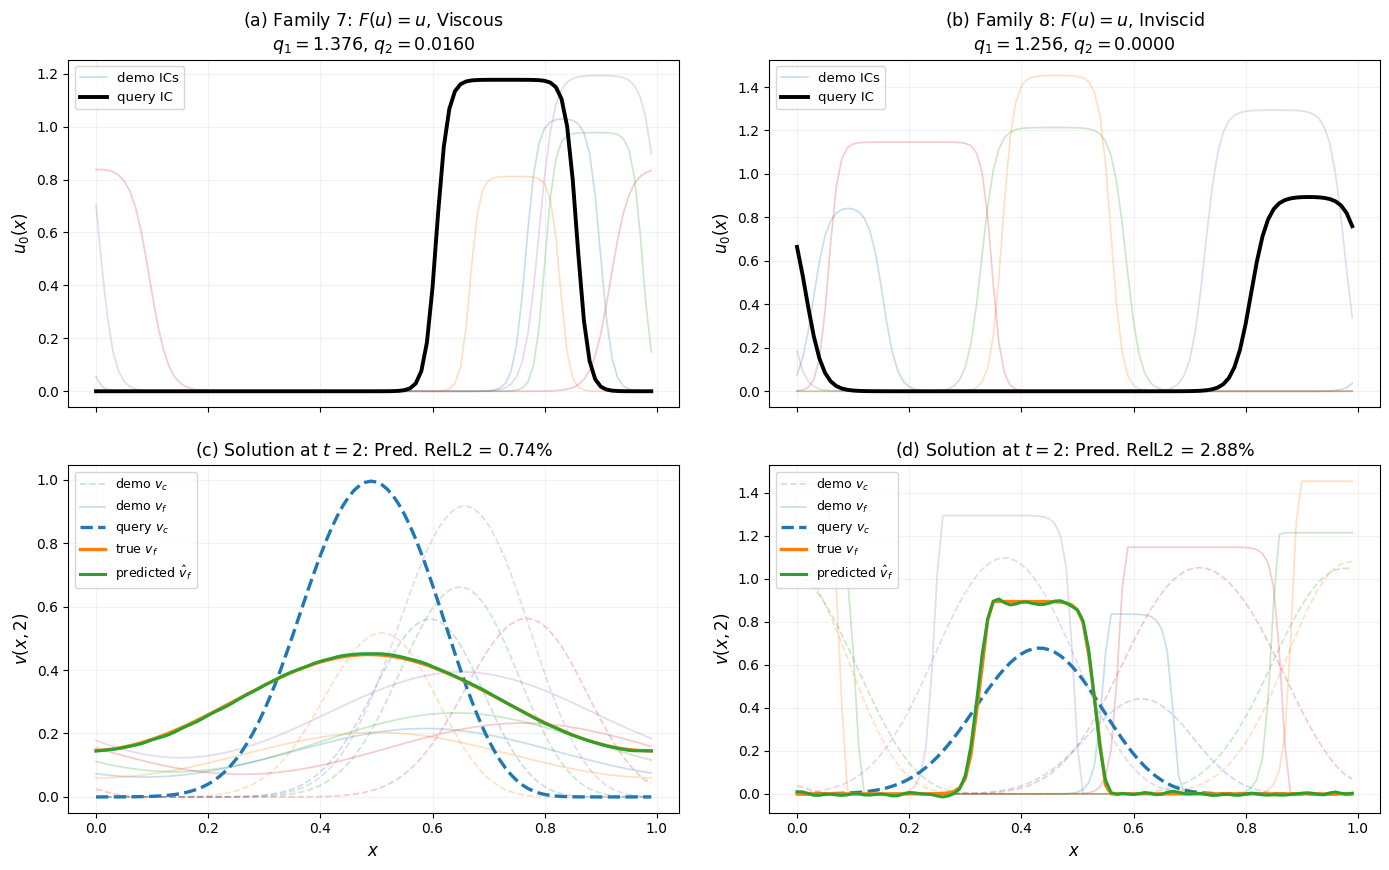


Saved:
  /kaggle/working/burgers_figure1_mixedK_pad17_latest/burgers_figure1_mixedK_pad17_latest.pdf
  /kaggle/working/burgers_figure1_mixedK_pad17_latest/burgers_figure1_mixedK_pad17_latest.png

DONE.


In [2]:
# ============================================================
# BURGERS REPRESENTATIVE FIGURE — LATEST MIXED-K PAD17 CHECKPOINT
#
# Fixed paper cases:
#   Family 7, fixed test case 519  -> F(u)=u, viscous
#   Family 8, fixed test case 428  -> F(u)=u, inviscid
#
# Layout:
#   (a,b) five demo ICs + query IC
#   (c,d) five demo uc/uf pairs + query uc + true uf + predicted uf
#
# The prediction errors are recomputed from the latest mixed-K PAD17
# FINAL epoch-300 checkpoint. No old prediction values are reused.
# ============================================================

from pathlib import Path
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 0. PATHS / SETTINGS
# ============================================================

DATASET_DIR = Path(
    "/kaggle/input/notebooks/xinyuanli913/dataset-box-ood"
)

CKPT_DIR = Path(
    "/kaggle/input/notebooks/xinyuanli913/burgers-training-padding"
)

DATASET_FILENAME = "all8families_box_linear_id_ampood_recorded.mat"

SAVE_DIR = Path(
    "/kaggle/working/burgers_figure1_mixedK_pad17_latest"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

PDF_PATH = SAVE_DIR / "burgers_figure1_mixedK_pad17_latest.pdf"
PNG_PATH = SAVE_DIR / "burgers_figure1_mixedK_pad17_latest.png"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_TEST_CASES = 1024
TEST_FIXED_DEMOS = 5
EPS = 1e-12

FAM7_CASE_INDEX = 519
FAM8_CASE_INDEX = 428

EXPECTED_FAMILY_COUNTS = [111, 120, 132, 114, 139, 134, 139, 135]


# ============================================================
# 1. LOCATE DATASET / CHECKPOINT
# ============================================================

dataset_candidates = list(DATASET_DIR.rglob(DATASET_FILENAME))
if len(dataset_candidates) != 1:
    print("Dataset candidates:")
    for p in DATASET_DIR.rglob("*.mat"):
        print(" ", p)
    raise RuntimeError(
        f"Expected exactly one {DATASET_FILENAME}; "
        f"found {len(dataset_candidates)}."
    )
MAT_PATH = dataset_candidates[0]

all_ckpts = sorted(CKPT_DIR.rglob("*.pt"))

preferred = [
    p for p in all_ckpts
    if "mixedK_pad17" in str(p)
    and "final_epoch300" in p.name
]

if len(preferred) != 1:
    preferred = [
        p for p in all_ckpts
        if "mixedK_pad17" in str(p)
        and "final" in p.name.lower()
        and "best" not in p.name.lower()
    ]

if len(preferred) != 1:
    print("Checkpoint candidates:")
    for p in all_ckpts:
        print(" ", p)
    raise RuntimeError(
        "Could not uniquely identify the final mixed-K PAD17 checkpoint."
    )

CKPT_PATH = preferred[0]

print("=" * 110)
print("BURGERS REPRESENTATIVE FIGURE | LATEST MIXED-K PAD17")
print("=" * 110)
print("Device     :", DEVICE)
print("Dataset    :", MAT_PATH)
print("Checkpoint :", CKPT_PATH)
print("Save dir   :", SAVE_DIR)


# ============================================================
# 2. LOAD DATASET
# ============================================================

mat = sio.loadmat(MAT_PATH)

for key in [
    "operators", "x", "pair_id",
    "u0_id", "uc_id", "uf_id", "ic_params_id"
]:
    if key not in mat:
        raise KeyError(f"Missing dataset key: {key}")

operators = np.asarray(mat["operators"], dtype=np.float32)
x_grid = np.asarray(mat["x"], dtype=np.float32).squeeze()
pair_id = np.asarray(mat["pair_id"], dtype=np.int64)
u0_id = np.asarray(mat["u0_id"], dtype=np.float32)
uc_id = np.asarray(mat["uc_id"], dtype=np.float32)
uf_id = np.asarray(mat["uf_id"], dtype=np.float32)
ic_params_id = np.asarray(mat["ic_params_id"], dtype=np.float32)

assert u0_id.shape == (8, 100, 100, 100)
assert uc_id.shape == u0_id.shape
assert uf_id.shape == u0_id.shape
assert operators.shape == (8, 100, 3)
assert x_grid.shape == (100,)

N_FAM = 8
N_VAR = 100
N_IC = 100
NX = 100

operators_flat = operators.reshape(800, 3)
flat_u0 = u0_id.reshape(800, 100, 100)
flat_uc = uc_id.reshape(800, 100, 100)
flat_uf = uf_id.reshape(800, 100, 100)
flat_pair_id = pair_id.reshape(800, 100)
flat_params = ic_params_id.reshape(800, 100, 4)

print("\n[dataset audit]")
print("  u0:", flat_u0.shape)
print("  uc:", flat_uc.shape)
print("  uf:", flat_uf.shape)
print("  x :", x_grid.shape)
print("  uc preprocessing: NONE")
print("  dataset already stores direct-linear 50 -> 100 coarse states")


# ============================================================
# 3. LOAD CHECKPOINT / NORMALIZATION
# ============================================================

try:
    ckpt = torch.load(
        CKPT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    ckpt = torch.load(
        CKPT_PATH,
        map_location="cpu",
    )

cfg = ckpt.get("config", {})
norm = ckpt["norm"]

SEED = int(cfg.get("SEED", 42))
MAX_CTX_ROWS = int(cfg.get("MAX_CTX_ROWS", 17))
N_ROW_TYPES = int(cfg.get("N_ROW_TYPES", 5))

D_MODEL = int(cfg.get("D_MODEL", 96))
N_HEAD = int(cfg.get("N_HEAD", 4))
N_LAYERS = int(cfg.get("N_LAYERS", 3))
D_FF = int(cfg.get("D_FF", 192))
DROPOUT = float(cfg.get("DROPOUT", 0.1))

TYPE_X_DEMO = int(cfg.get("TYPE_X_DEMO", 0))
TYPE_UC_DEMO = int(cfg.get("TYPE_UC_DEMO", 1))
TYPE_UF_DEMO = int(cfg.get("TYPE_UF_DEMO", 2))
TYPE_X_QUERY = int(cfg.get("TYPE_X_QUERY", 3))
TYPE_UC_QUERY = int(cfg.get("TYPE_UC_QUERY", 4))

x_mean = float(norm["x_mean"])
x_std = float(norm["x_std"])
uc_mean = float(norm["uc_mean"])
uc_std = float(norm["uc_std"])
uf_mean = float(norm["uf_mean"])
uf_std = float(norm["uf_std"])

x_n = ((x_grid - x_mean) / x_std).astype(np.float32)
uc_n = ((flat_uc - uc_mean) / uc_std).astype(np.float32)
uf_n = ((flat_uf - uf_mean) / uf_std).astype(np.float32)

print("\n[checkpoint audit]")
print("  seed       :", SEED)
print("  d_model    :", D_MODEL)
print("  heads      :", N_HEAD)
print("  layers     :", N_LAYERS)
print("  D_FF       :", D_FF)
print("  dropout    :", DROPOUT)
print("  max rows   :", MAX_CTX_ROWS)


# ============================================================
# 4. MODEL
# ============================================================

class RowSequenceWholeBlockShiftTransformer(nn.Module):
    def __init__(
        self,
        nx=100,
        max_ctx_rows=17,
        n_row_types=5,
        d_model=96,
        nhead=4,
        num_layers=3,
        dim_ff=192,
        dropout=0.1,
    ):
        super().__init__()

        self.row_in = nn.Linear(nx, d_model)
        self.row_type_emb = nn.Embedding(n_row_types, d_model)
        self.pos_emb = nn.Embedding(max_ctx_rows, d_model)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            activation=torch.tanh,
            batch_first=True,
            norm_first=True,
        )

        self.encoder = nn.TransformerEncoder(
            enc_layer,
            num_layers=num_layers,
        )

        self.row_out = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model),
            nn.Tanh(),
            nn.Linear(d_model, nx),
        )

        self.register_buffer(
            "pos_ids",
            torch.arange(max_ctx_rows, dtype=torch.long),
            persistent=False,
        )

    def forward(
        self,
        mat_ctx,
        row_type_arr,
        src_key_padding_mask=None,
    ):
        _, S, _ = mat_ctx.shape

        h = self.row_in(mat_ctx)
        h = h + self.row_type_emb(row_type_arr)
        h = h + self.pos_emb(self.pos_ids[:S])[None, :, :]

        h = self.encoder(
            h,
            src_key_padding_mask=src_key_padding_mask,
        )

        return self.row_out(h)


model = RowSequenceWholeBlockShiftTransformer(
    nx=NX,
    max_ctx_rows=MAX_CTX_ROWS,
    n_row_types=N_ROW_TYPES,
    d_model=D_MODEL,
    nhead=N_HEAD,
    num_layers=N_LAYERS,
    dim_ff=D_FF,
    dropout=DROPOUT,
).to(DEVICE)

model.load_state_dict(
    ckpt["model"],
    strict=True,
)

model.eval()

n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("  parameters :", f"{n_params:,}")
assert n_params == 255364


# ============================================================
# 5. EXACT 70/30 OPERATOR SPLIT
# ============================================================

if "train_ops" in cfg and "test_ops" in cfg:

    train_ops = np.asarray(
        cfg["train_ops"],
        dtype=np.int64,
    )

    test_ops = np.asarray(
        cfg["test_ops"],
        dtype=np.int64,
    )

else:

    rng_ops = np.random.default_rng(SEED)

    train_ops_list = []
    test_ops_list = []

    for fam in range(N_FAM):
        perm = rng_ops.permutation(N_VAR)

        train_var = perm[:70]
        test_var = perm[70:]

        train_ops_list.extend(
            fam * N_VAR + int(v)
            for v in train_var
        )

        test_ops_list.extend(
            fam * N_VAR + int(v)
            for v in test_var
        )

    train_ops = np.asarray(
        train_ops_list,
        dtype=np.int64,
    )

    test_ops = np.asarray(
        test_ops_list,
        dtype=np.int64,
    )

assert len(train_ops) == 560
assert len(test_ops) == 240

all_ics = np.arange(N_IC, dtype=np.int64)


# ============================================================
# 6. EXACT FIXED 1024-CASE TEST BANK
# ============================================================

def make_fixed_cases(
    op_pool,
    ic_pool,
    n_cases,
    seed,
    fixed_demos,
):
    r = np.random.default_rng(seed)

    cases = []

    for _ in range(n_cases):
        op = int(r.choice(op_pool))

        idxs = r.choice(
            ic_pool,
            size=fixed_demos + 1,
            replace=False,
        )

        demo_idx = np.asarray(
            idxs[:fixed_demos],
            dtype=np.int64,
        )

        query_idx = int(idxs[-1])

        cases.append(
            (
                op,
                demo_idx,
                query_idx,
            )
        )

    return cases


CASE_SEED = SEED + 1

test_cases = make_fixed_cases(
    op_pool=test_ops,
    ic_pool=all_ics,
    n_cases=N_TEST_CASES,
    seed=CASE_SEED,
    fixed_demos=TEST_FIXED_DEMOS,
)

case_families = np.asarray(
    [
        op // N_VAR + 1
        for op, _, _ in test_cases
    ],
    dtype=np.int64,
)

family_counts = [
    int(np.sum(case_families == fam))
    for fam in range(1, 9)
]

print("\nFixed 1024-case family counts:", family_counts)

if family_counts != EXPECTED_FAMILY_COUNTS:
    raise RuntimeError(
        "Fixed 1024-case bank does not match the official protocol."
    )

print("Family-count audit: PASS")


# ============================================================
# 7. BUILD K=5 CONTEXT
# ============================================================

def build_context(
    op,
    demo_idx,
    query_idx,
):
    rows = []
    row_types = []

    for di in demo_idx:
        rows.append(x_n)
        row_types.append(TYPE_X_DEMO)

        rows.append(uc_n[op, di])
        row_types.append(TYPE_UC_DEMO)

        rows.append(uf_n[op, di])
        row_types.append(TYPE_UF_DEMO)

    rows.append(x_n)
    row_types.append(TYPE_X_QUERY)

    rows.append(uc_n[op, query_idx])
    row_types.append(TYPE_UC_QUERY)

    mat_ctx = np.stack(
        rows,
        axis=0,
    ).astype(np.float32)

    row_type_arr = np.asarray(
        row_types,
        dtype=np.int64,
    )

    assert mat_ctx.shape == (17, NX)

    return mat_ctx, row_type_arr


def rel_l2_percent(pred, true):
    return float(
        100.0
        * np.linalg.norm(pred - true)
        / (np.linalg.norm(true) + EPS)
    )


# ============================================================
# 8. EVALUATE CASES 519 AND 428
# ============================================================

SELECTED_CASES = [
    {
        "case_index": FAM7_CASE_INDEX,
        "expected_family": 7,
        "regime": "Viscous",
    },
    {
        "case_index": FAM8_CASE_INDEX,
        "expected_family": 8,
        "regime": "Inviscid",
    },
]


@torch.no_grad()
def evaluate_selected_case(spec):

    case_index = int(spec["case_index"])

    op, demo_idx, query_idx = test_cases[case_index]

    family = op // N_VAR + 1

    if family != int(spec["expected_family"]):
        raise RuntimeError(
            f"Case {case_index} reconstructed as Family {family}, "
            f"expected Family {spec['expected_family']}."
        )

    ctx, row_types = build_context(
        op,
        demo_idx,
        query_idx,
    )

    ctx_t = torch.from_numpy(
        ctx[None, ...]
    ).to(DEVICE)

    row_types_t = torch.from_numpy(
        row_types[None, ...]
    ).to(DEVICE)

    # K=5 -> all 17 rows are valid, so there are no padded rows.
    pred_all_n = model(
        ctx_t,
        row_types_t,
        src_key_padding_mask=None,
    )

    pred_n = pred_all_n[
        0,
        -1,
        :,
    ]

    pred = (
        pred_n
        * uf_std
        + uf_mean
    ).detach().cpu().numpy().astype(np.float32)

    query_uf = flat_uf[
        op,
        query_idx,
    ]

    return {
        **spec,

        "op": int(op),
        "operator_index_in_family": int(op % N_VAR),
        "demo_idx": np.asarray(demo_idx, dtype=np.int64),
        "query_idx": int(query_idx),

        "q1": float(operators_flat[op, 0]),
        "q2": float(operators_flat[op, 1]),
        "flux_type": int(round(float(operators_flat[op, 2]))),

        "demo_u0": flat_u0[op, demo_idx],
        "demo_uc": flat_uc[op, demo_idx],
        "demo_uf": flat_uf[op, demo_idx],

        "query_u0": flat_u0[op, query_idx],
        "query_uc": flat_uc[op, query_idx],
        "query_uf": query_uf,
        "pred": pred,

        "pred_rel": rel_l2_percent(
            pred,
            query_uf,
        ),

        "query_pair_id": int(
            flat_pair_id[op, query_idx]
        ),

        "query_params": flat_params[
            op,
            query_idx,
        ].copy(),
    }


results = [
    evaluate_selected_case(spec)
    for spec in SELECTED_CASES
]

print("\n[selected-case audit]")

for r in results:
    print(
        f"case={r['case_index']} | "
        f"family={r['expected_family']} | "
        f"op={r['op']} | "
        f"var={r['operator_index_in_family']} | "
        f"query_ic={r['query_idx']} | "
        f"q1={r['q1']:.6f} | "
        f"q2={r['q2']:.6f} | "
        f"Pred RelL2={r['pred_rel']:.6f}%"
    )

# Exact audits for the two paper representatives.
assert results[0]["case_index"] == 519
assert results[0]["expected_family"] == 7
assert abs(results[0]["q1"] - 1.3763418) < 5e-6
assert abs(results[0]["q2"] - 0.01602694) < 5e-6

assert results[1]["case_index"] == 428
assert results[1]["expected_family"] == 8
assert results[1]["op"] == 774
assert results[1]["operator_index_in_family"] == 74
assert results[1]["query_idx"] == 49
assert abs(results[1]["q1"] - 1.2562679) < 5e-6
assert abs(results[1]["q2"]) < 1e-12

print("\nRepresentative-case audit: PASS")
print("  Left : case 519, Family 7, q1≈1.376, q2≈0.0160")
print("  Right: case 428, Family 8, q1≈1.256, q2=0")


# ============================================================
# 9. PLOT
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14.0, 8.8),
    sharex="col",
)

ax_a = axes[0, 0]
ax_b = axes[0, 1]
ax_c = axes[1, 0]
ax_d = axes[1, 1]

DEMO_ALPHA = 0.24
DEMO_LW = 1.25

QUERY_IC_LW = 2.8
QUERY_UC_LW = 2.4
TRUE_UF_LW = 2.4
PRED_UF_LW = 2.2

demo_colors = [
    plt.get_cmap("tab10")(j)
    for j in range(TEST_FIXED_DEMOS)
]


# ------------------------------------------------------------
# Top row: demo ICs + query IC
# ------------------------------------------------------------

for r, ax in zip(
    results,
    [ax_a, ax_b],
):

    for j in range(TEST_FIXED_DEMOS):
        ax.plot(
            x_grid,
            r["demo_u0"][j],
            linewidth=DEMO_LW,
            alpha=DEMO_ALPHA,
            color=demo_colors[j],
        )

    ax.plot(
        x_grid,
        r["query_u0"],
        linewidth=QUERY_IC_LW,
        color="black",
    )

    demo_handle = Line2D(
        [0], [0],
        linewidth=DEMO_LW,
        alpha=DEMO_ALPHA,
        color="tab:blue",
        label="demo ICs",
    )

    query_handle = Line2D(
        [0], [0],
        linewidth=QUERY_IC_LW,
        color="black",
        label="query IC",
    )

    ax.legend(
        handles=[
            demo_handle,
            query_handle,
        ],
        loc="upper left",
        fontsize=9.5,
        frameon=True,
    )

    ax.set_ylabel(
        r"$u_0(x)$",
        fontsize=12,
    )

    ax.grid(
        True,
        alpha=0.16,
    )


ax_a.set_title(
    (
        r"(a) Family 7: $F(u)=u$, Viscous"
        "\n"
        rf"$q_1={results[0]['q1']:.3f}$, "
        rf"$q_2={results[0]['q2']:.4f}$"
    ),
    fontsize=12.5,
    pad=7,
)

ax_b.set_title(
    (
        r"(b) Family 8: $F(u)=u$, Inviscid"
        "\n"
        rf"$q_1={results[1]['q1']:.3f}$, "
        rf"$q_2={results[1]['q2']:.4f}$"
    ),
    fontsize=12.5,
    pad=7,
)


# ------------------------------------------------------------
# Bottom row: demos + query / true / prediction
# ------------------------------------------------------------

for r, ax in zip(
    results,
    [ax_c, ax_d],
):

    for j in range(TEST_FIXED_DEMOS):

        ax.plot(
            x_grid,
            r["demo_uc"][j],
            linestyle="--",
            linewidth=DEMO_LW,
            alpha=DEMO_ALPHA,
            color=demo_colors[j],
        )

        ax.plot(
            x_grid,
            r["demo_uf"][j],
            linestyle="-",
            linewidth=DEMO_LW,
            alpha=DEMO_ALPHA,
            color=demo_colors[j],
        )

    query_line, = ax.plot(
        x_grid,
        r["query_uc"],
        linestyle="--",
        linewidth=QUERY_UC_LW,
        color="tab:blue",
        label=r"query $v_c$",
    )

    true_line, = ax.plot(
        x_grid,
        r["query_uf"],
        linestyle="-",
        linewidth=TRUE_UF_LW,
        color="tab:orange",
        label=r"true $v_f$",
    )

    pred_line, = ax.plot(
        x_grid,
        r["pred"],
        linestyle="-",
        linewidth=PRED_UF_LW,
        color="tab:green",
        label=r"predicted $\hat{v}_f$",
    )

    demo_uc_handle = Line2D(
        [0], [0],
        linestyle="--",
        linewidth=DEMO_LW,
        alpha=DEMO_ALPHA,
        color="tab:blue",
        label=r"demo $v_c$",
    )

    demo_uf_handle = Line2D(
        [0], [0],
        linestyle="-",
        linewidth=DEMO_LW,
        alpha=DEMO_ALPHA,
        color="tab:blue",
        label=r"demo $v_f$",
    )

    ax.legend(
        handles=[
            demo_uc_handle,
            demo_uf_handle,
            query_line,
            true_line,
            pred_line,
        ],
        loc="upper left",
        fontsize=9.0,
        frameon=True,
    )

    ax.set_xlabel(
        r"$x$",
        fontsize=12,
    )

    ax.set_ylabel(
        r"$v(x,2)$",
        fontsize=12,
    )

    ax.grid(
        True,
        alpha=0.16,
    )


ax_c.set_title(
    (
        r"(c) Solution at $t=2$: "
        rf"Pred. RelL2 = {results[0]['pred_rel']:.2f}%"
    ),
    fontsize=12.5,
    pad=7,
)

ax_d.set_title(
    (
        r"(d) Solution at $t=2$: "
        rf"Pred. RelL2 = {results[1]['pred_rel']:.2f}%"
    ),
    fontsize=12.5,
    pad=7,
)


# ============================================================
# 10. GLOBAL STYLE / SAVE
# ============================================================

for ax in axes.ravel():
    ax.tick_params(
        axis="both",
        labelsize=10,
    )

plt.tight_layout(
    h_pad=2.0,
    w_pad=2.3,
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nSaved:")
print(" ", PDF_PATH)
print(" ", PNG_PATH)
print("\nDONE.")